# 03 — Segmentação de imóveis em King County

O objetivo deste estudo é identificar perfis de imóveis com características físicas semelhantes, apoiando a organização de uma carteira imobiliária por dimensão, equipamento, qualidade de construção e estado de conservação. Esta segmentação fornece uma base para comparar imóveis dentro de perfis semelhantes.

A análise aplica o algoritmo K-Means a uma observação por imóvel. O número de clusters é selecionado com base na silhouette, complementando-se a avaliação pela análise da inércia, da dimensão dos grupos e dos perfis obtidos. O preço é utilizado na caracterização posterior dos grupos.

## 1. Dados e unidade de análise

Os dados provêm de [House Sales in King County, USA](https://www.kaggle.com/datasets/harlfoxem/housesalesprediction) e correspondem a vendas realizadas entre maio de 2014 e maio de 2015 no condado de King, no estado de Washington, Estados Unidos. O carregamento dá prioridade ao ficheiro preparado `data/kingcounty/kc_clean.csv`, recorrendo ao CSV original quando esse ficheiro não está disponível.

A unidade de análise é o imóvel, identificado por `id`. Para evitar que as revendas atribuam peso adicional ao mesmo imóvel, conserva-se a observação com a data de venda mais recente. A consistência das características usadas no clustering é verificada entre as vendas de cada id repetido.

A preparação mantém a correção de `bedrooms = 33` para `3`, adotada na análise exploratória como hipótese de tratamento de um registo atípico. Os valores zero de quartos e casas de banho são conservados e contabilizados na auditoria dos dados.

A tabela seguinte documenta o número de vendas, os imóveis com observações repetidas, as correções aplicadas e a dimensão final da amostra. A origem e o resumo SHA-256 do CSV identificam os dados utilizados na execução.

In [1]:
from pathlib import Path
from io import BytesIO
from urllib.request import Request, urlopen
from zipfile import ZipFile
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats

get_ipython().run_line_magic("matplotlib", "inline")
set_matplotlib_formats("svg")
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.2})

CAMINHO_PREPARADO = Path("data/kingcounty/kc_clean.csv")
URL_DADOS = "https://www.kaggle.com/api/v1/datasets/download/harlfoxem/housesalesprediction"
PERMITIR_DOWNLOAD = True
SEMENTE = 42

if CAMINHO_PREPARADO.is_file():
    conteudo = CAMINHO_PREPARADO.read_bytes()
    fonte = str(CAMINHO_PREPARADO.resolve())
    fonte_preparada = True
elif PERMITIR_DOWNLOAD:
    pedido = Request(URL_DADOS, headers={"User-Agent": "KingCountyAcademicNotebook/1.0"})
    with urlopen(pedido, timeout=90) as resposta:
        arquivo = resposta.read()
    with ZipFile(BytesIO(arquivo)) as zip_dados:
        candidatos = [
            nome for nome in zip_dados.namelist()
            if Path(nome).name == "kc_house_data.csv"
        ]
        if len(candidatos) != 1:
            raise ValueError("O arquivo deve conter exatamente um kc_house_data.csv.")
        conteudo = zip_dados.read(candidatos[0])
    fonte = URL_DADOS + " → kc_house_data.csv"
    fonte_preparada = False
else:
    raise FileNotFoundError(
        "Coloca kc_clean.csv em data/kingcounty ou ativa PERMITIR_DOWNLOAD."
    )

df = pd.read_csv(BytesIO(conteudo), dtype={"id": "string"})
VARIAVEIS = ["bedrooms", "bathrooms", "sqft_living", "grade", "condition"]
DESCRITORES = ["price", "waterfront", "view", "yr_built", "yr_renovated", "zipcode"]
necessarias = ["id", "date"] + VARIAVEIS + DESCRITORES
em_falta = sorted(set(necessarias) - set(df.columns))
if em_falta:
    raise ValueError(f"Colunas em falta: {em_falta}")

# O CSV original codifica a data como AAAAMMDDT000000; o preparado usa datas ISO.
df["date"] = pd.to_datetime(
    df["date"] if fonte_preparada else df["date"].astype("string").str[:8],
    format=None if fonte_preparada else "%Y%m%d",
    errors="coerce",
)
if df["id"].isna().any() or df["date"].isna().any():
    raise ValueError("Existem imóveis sem id ou data válidos; é necessário rever a fonte.")
if df.duplicated(["id", "date"]).any():
    raise ValueError("Há vendas repetidas para o mesmo id e data; revê-as antes de avançar.")

for coluna in VARIAVEIS:
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")
corrigidos = int(df["bedrooms"].eq(33).sum())
df.loc[df["bedrooms"].eq(33), "bedrooms"] = 3

repetidos = df.loc[df.duplicated("id", keep=False)]
mudancas = repetidos.groupby("id")[VARIAVEIS].nunique(dropna=False).gt(1).any(axis=1)
casas = (
    df.sort_values(["id", "date"], kind="stable")
    .drop_duplicates("id", keep="last")
    .reset_index(drop=True)
)

auditoria = pd.Series({
    "linhas na fonte": len(df),
    "ids com várias vendas": repetidos["id"].nunique(),
    "linhas desses ids": len(repetidos),
    "máximo de vendas por id": df.groupby("id").size().max(),
    "ids repetidos com alteração nas variáveis escolhidas": int(mudancas.sum()),
    "correções 33 → 3 aplicadas nesta execução": corrigidos,
    "casas distintas usadas": len(casas),
    "vendas adicionais sem peso extra no clustering": len(df) - len(casas),
}, name="valor")
print("Fonte:", fonte)
print("SHA-256 do CSV:", hashlib.sha256(conteudo).hexdigest())
print("Período:", df["date"].min().date(), "a", df["date"].max().date())
display(auditoria.to_frame())
if mudancas.any():
    print("Atenção: há alterações físicas registadas; usamos o estado da última venda.")
assert casas["id"].is_unique


Fonte: https://www.kaggle.com/api/v1/datasets/download/harlfoxem/housesalesprediction → kc_house_data.csv
SHA-256 do CSV: d0875baa0251b21d4bdc9d2ae940a4fe0bb6009824f23dd0e2a5b2bf04557b7e
Período: 2014-05-02 a 2015-05-27


,valor
linhas na fonte,21613
ids com várias vendas,176
linhas desses ids,353
máximo de vendas por id,3
ids repetidos com alteração nas variáveis escolhidas,0
correções 33 → 3 aplicadas nesta execução,1
casas distintas usadas,21436
vendas adicionais sem peso extra no clustering,177


## 2. Seleção e preparação das variáveis

A segmentação utiliza cinco variáveis:

| Variável | Característica representada |
|---|---|
| `bedrooms` | Número de quartos |
| `bathrooms` | Número de casas de banho |
| `sqft_living` | Área habitável, em pés quadrados |
| `grade` | Qualidade da construção, numa escala de 1 a 13 |
| `condition` | Estado de conservação, numa escala de 1 a 5 |

Estas variáveis descrevem dimensão, equipamento e conservação. A área habitável representa a dimensão total da habitação; as suas componentes acima do solo e na cave são excluídas para reduzir a redundância. O preço e as variáveis derivadas da classificação de preço são reservados para interpretação posterior. O identificador e a data servem para estabelecer a unidade de análise.

A área habitável é transformada através de `log1p`, reduzindo a influência da assimetria da distribuição. Em seguida, cada variável é normalizada pela diferença face à média, dividida pelo desvio padrão populacional (`ddof=0`). Este procedimento uniformiza as escalas utilizadas no cálculo das distâncias euclidianas.

O tratamento de valores ausentes ou não finitos prevê a substituição pela mediana da respetiva variável. A tabela de preparação regista a frequência destes valores, dos zeros e dos extremos observados. A matriz final é validada antes da aplicação do algoritmo.

In [2]:
valores = casas[VARIAVEIS].replace([np.inf, -np.inf], np.nan).copy()
resumo_preparacao = pd.DataFrame({
    "ausentes_ou_não_finitos": valores.isna().sum(),
    "zeros": valores.eq(0).sum(),
    "mínimo": valores.min(),
    "máximo": valores.max(),
    "mediana_de_imputação": valores.median(),
})
display(resumo_preparacao)
if valores.median().isna().any():
    raise ValueError("Existe uma variável sem valores válidos para calcular a mediana.")
if (valores[["bedrooms", "bathrooms"]] < 0).any().any():
    raise ValueError("Quartos e casas de banho não podem ser negativos.")
if (valores["sqft_living"].dropna() <= 0).any():
    raise ValueError("A área habitável deve ser positiva.")
if (not valores["grade"].dropna().between(1, 13).all()
        or not valores["condition"].dropna().between(1, 5).all()):
    raise ValueError("Qualidade ou estado fora das escalas esperadas.")

valores = valores.fillna(valores.median())
transformados = valores.copy()
transformados["sqft_living"] = np.log1p(transformados["sqft_living"])
media = transformados.mean()
desvio = transformados.std(ddof=0)
constantes = desvio.index[desvio.eq(0)].tolist()
# Uma variável constante fica a zero e não afeta a distância.
X = ((transformados - media) / desvio.mask(desvio.eq(0), 1)).to_numpy(dtype=float)
assert np.isfinite(X).all()
print("Matriz:", X.shape, "| variáveis constantes:", constantes or "nenhuma")
display(pd.DataFrame(X, columns=VARIAVEIS).agg(["mean", "std"]).round(3))


,ausentes_ou_não_finitos,zeros,mínimo,máximo,mediana_de_imputação
bedrooms,0,13,0.0,11.0,3.00
bathrooms,0,10,0.0,8.0,2.25
sqft_living,0,0,290.0,13540.0,1920.00
grade,0,0,1.0,13.0,7.00
condition,0,0,1.0,5.0,3.00


Matriz: (21436, 5) | variáveis constantes: nenhuma


,bedrooms,bathrooms,sqft_living,grade,condition
mean,-0.0,-0.0,-0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0


## 3. Implementação do K-Means

O K-Means procura minimizar a soma das distâncias euclidianas quadráticas entre cada observação e o centro do cluster a que pertence. Em cada inicialização, o procedimento seleciona K observações distintas como centros, atribui os imóveis ao centro mais próximo e recalcula os centros pela média dos respetivos membros.

Estas operações repetem-se até que as atribuições permaneçam estáveis e o deslocamento máximo dos centros seja inferior ou igual a `10⁻⁶`, com um limite de 300 iterações. Um cluster vazio é reinicializado num ponto afastado dos centros ocupados. São realizadas dez inicializações por valor de K, conservando-se a solução convergente com menor inércia. A experiência principal utiliza a semente 42.

O algoritmo e as métricas de avaliação são implementados neste notebook. NumPy e pandas suportam as operações numéricas e a manipulação dos dados; Matplotlib é utilizado na representação gráfica. Um exemplo com centros e inércia conhecidos verifica o funcionamento da implementação.

In [3]:
def distancias_quadradas(X, centros):
    # A matriz tem n × K valores, sem criar um tensor n × K × variáveis.
    return np.column_stack([
        np.sum((X - centro) ** 2, axis=1) for centro in centros
    ])


def kmeans_raiz(X, k, semente=42, n_init=10, max_iter=300, tolerancia=1e-6):
    X = np.asarray(X, dtype=float)
    if (X.ndim != 2 or X.shape[0] == 0 or X.shape[1] == 0
            or not np.isfinite(X).all()):
        raise ValueError("X deve ser uma matriz não vazia e finita.")
    for nome, valor in [("k", k), ("n_init", n_init), ("max_iter", max_iter)]:
        if isinstance(valor, bool) or not isinstance(valor, (int, np.integer)) or valor < 1:
            raise ValueError(f"{nome} deve ser um inteiro positivo.")
    if not np.isfinite(tolerancia) or tolerancia < 0:
        raise ValueError("A tolerância deve ser finita e não negativa.")

    distintos = np.unique(X, axis=0)
    if k > len(distintos):
        raise ValueError("K excede o número de pontos distintos.")
    rng = np.random.default_rng(semente)
    melhor = None
    tentativas = []

    for tentativa in range(n_init):
        centros = distintos[rng.choice(len(distintos), size=k, replace=False)].copy()
        historico = []
        convergiu = False

        for iteracao in range(1, max_iter + 1):
            distancias = distancias_quadradas(X, centros)
            grupos = distancias.argmin(axis=1)
            novos = centros.copy()
            vazios = []

            for grupo in range(k):
                membros = X[grupos == grupo]
                if len(membros):
                    novos[grupo] = membros.mean(axis=0)
                else:
                    vazios.append(grupo)

            if vazios:
                ocupados = [grupo for grupo in range(k) if grupo not in vazios]
                proximidade = distancias_quadradas(X, novos[ocupados]).min(axis=1)
                for grupo in vazios:
                    indice = int(proximidade.argmax())
                    novos[grupo] = X[indice]
                    # Atualiza as distâncias para não repetir o ponto na próxima reinicialização.
                    proximidade = np.minimum(
                        proximidade, distancias_quadradas(X, [X[indice]])[:, 0]
                    )

            deslocamento = np.linalg.norm(novos - centros, axis=1).max()
            centros = novos
            distancias = distancias_quadradas(X, centros)
            novos_grupos = distancias.argmin(axis=1)
            inercia = float(distancias[np.arange(len(X)), novos_grupos].sum())
            historico.append(inercia)

            # Verifica também as atribuições, para que os centros finais correspondam aos grupos.
            if (not vazios and deslocamento <= tolerancia
                    and np.array_equal(grupos, novos_grupos)):
                convergiu = True
                break

        grupos = novos_grupos
        completo = len(np.unique(grupos)) == k
        tentativas.append({
            "tentativa": tentativa, "inercia": inercia,
            "iterações": iteracao, "convergiu": convergiu,
            "grupos_não_vazios": completo,
        })
        if convergiu and completo and (melhor is None or inercia < melhor["inercia"]):
            melhor = {
                "centros": centros.copy(), "grupos": grupos.copy(),
                "inercia": inercia, "iteracoes": iteracao,
                "historico": historico.copy(), "convergiu": True,
            }

    if melhor is None:
        raise RuntimeError(
            "Nenhuma tentativa convergiu com K grupos. Revê K, os dados ou max_iter."
        )
    melhor["tentativas"] = pd.DataFrame(tentativas)
    return melhor

In [4]:
teste = kmeans_raiz(np.array([[0.0], [2.0], [10.0], [12.0]]), 2)
np.testing.assert_allclose(np.sort(teste["centros"].ravel()), [1, 11])
assert np.isclose(teste["inercia"], 4)
assert len(np.unique(teste["grupos"])) == 2
print("Verificação do exemplo conhecido: passou.")

Verificação do exemplo conhecido: passou.


## 4. Avaliação do número de clusters

São avaliados os valores de K entre 2 e 8, mantendo a preparação dos dados e dez inicializações por configuração. A comparação considera a inércia, a silhouette, a dimensão dos grupos e a convergência das tentativas.

A inércia mede a soma das distâncias quadráticas aos centros. A sua evolução permite observar a redução da dispersão interna à medida que aumenta o número de clusters. A silhouette compara a distância média de uma observação aos membros do seu grupo com a menor distância média a outro grupo; valores superiores indicam maior separação segundo a distância adotada.

A silhouette é calculada numa amostra aleatória fixa de até 500 imóveis, comum a todos os valores de K. As distâncias são calculadas entre os elementos dessa amostra, reduzindo o custo computacional. Uma configuração só recebe pontuação quando todos os seus clusters estão representados na amostra.

O valor de K com maior silhouette válida é selecionado para a caracterização dos perfis. A tabela e os gráficos apresentam os resultados intermédios da comparação.

In [5]:
def silhouette_raiz(X, grupos):
    X = np.asarray(X, dtype=float)
    grupos = np.asarray(grupos)
    if (X.ndim != 2 or grupos.ndim != 1 or len(X) != len(grupos)
            or not np.isfinite(X).all()):
        raise ValueError("X e grupos devem estar alinhados e ter valores válidos.")
    distintos = np.unique(grupos)
    if not 2 <= len(distintos) < len(X):
        raise ValueError("A silhouette exige entre 2 e n-1 grupos.")

    distancias = np.sqrt(distancias_quadradas(X, X))
    valores = np.zeros(len(X))

    for i in range(len(X)):
        mesmo = grupos == grupos[i]
        if mesmo.sum() == 1:
            continue
        a = distancias[i, mesmo].sum() / (mesmo.sum() - 1)
        b = min(
            distancias[i, grupos == outro].mean()
            for outro in distintos if outro != grupos[i]
        )
        valores[i] = (b - a) / max(a, b) if max(a, b) > 0 else 0.0

    return float(valores.mean())


esperado = ((1 - 2 / 11) + (1 - 2 / 9)) / 2
assert np.isclose(
    silhouette_raiz([[0], [2], [10], [12]], [0, 0, 1, 1]), esperado
)
print("Verificação da silhouette: passou.")

Verificação da silhouette: passou.


,inércia,silhouette_amostra,grupos_na_amostra,menor_grupo,maior_grupo,iterações_da_melhor,tentativas_convergentes
K,,,,,,,
2,68726.1458,0.3372,2,10173,11263,14,10
3,56779.7347,0.2836,3,5676,7899,20,10
4,46188.4610,0.2434,4,4075,7537,40,10
5,41267.0812,0.2502,5,3394,7015,48,10
6,37418.0421,0.2438,6,2134,5291,65,10
7,34262.0384,0.2459,7,1236,4607,47,10
8,31820.6959,0.2577,8,1187,4556,35,10


K candidato pelo maior valor de silhouette na amostra: 2


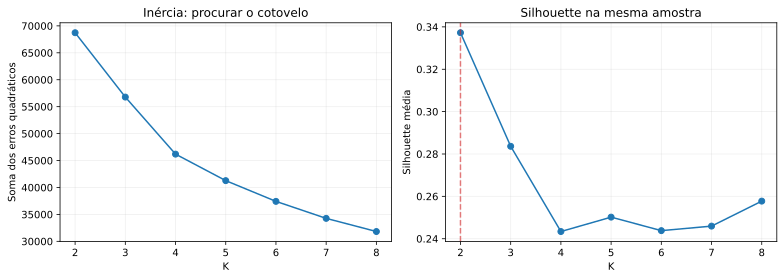

In [6]:
KS = list(range(2, 9))
N_INICIALIZACOES = 10
MAX_ITERACOES = 300
indices_amostra = np.random.default_rng(SEMENTE).choice(
    len(X), size=min(500, len(X)), replace=False
)
modelos = {}
linhas = []
for k in KS:
    modelo = kmeans_raiz(
        X, k, semente=SEMENTE,
        n_init=N_INICIALIZACOES, max_iter=MAX_ITERACOES
    )
    modelos[k] = modelo
    rotulos_amostra = modelo["grupos"][indices_amostra]
    grupos_presentes = len(np.unique(rotulos_amostra))
    pontuacao = (
        silhouette_raiz(X[indices_amostra], rotulos_amostra)
        if grupos_presentes == k and k < len(indices_amostra) else np.nan
    )
    tamanhos = np.bincount(modelo["grupos"], minlength=k)
    linhas.append({
        "K": k,
        "inércia": modelo["inercia"],
        "silhouette_amostra": pontuacao,
        "grupos_na_amostra": grupos_presentes,
        "menor_grupo": int(tamanhos.min()),
        "maior_grupo": int(tamanhos.max()),
        "iterações_da_melhor": modelo["iteracoes"],
        "tentativas_convergentes": int(modelo["tentativas"]["convergiu"].sum()),
    })

comparacao = pd.DataFrame(linhas).set_index("K")
display(comparacao.round(4))
validos = comparacao.dropna(subset=["silhouette_amostra"])
if validos.empty:
    raise RuntimeError("A amostra não permite comparar K; aumenta o tamanho da amostra.")
K_ESCOLHIDO = int(validos["silhouette_amostra"].idxmax())
melhor = modelos[K_ESCOLHIDO]
print("K candidato pelo maior valor de silhouette na amostra:", K_ESCOLHIDO)

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
eixos[0].plot(comparacao.index, comparacao["inércia"], "o-")
eixos[0].set(title="Inércia: procurar o cotovelo", xlabel="K", ylabel="Soma dos erros quadráticos")
eixos[1].plot(comparacao.index, comparacao["silhouette_amostra"], "o-")
eixos[1].axvline(K_ESCOLHIDO, color="tab:red", linestyle="--", alpha=0.6)
eixos[1].set(title="Silhouette na mesma amostra", xlabel="K", ylabel="Silhouette média")
for eixo in eixos:
    eixo.set_xticks(KS)
fig.tight_layout()
plt.show()


## 5. Caracterização dos clusters

A caracterização apresenta a dimensão de cada cluster, a sua proporção na amostra e as medianas das variáveis físicas. Os percentis 25 e 75 complementam a descrição da dispersão interna. A área habitável é também expressa em metros quadrados, utilizando o fator de conversão de 0,09290304 m² por pé quadrado.

O mapa de calor representa os centros na escala transformada e normalizada. Valores positivos e negativos indicam posições acima e abaixo da média, respetivamente. Na variável de área, esta representação corresponde ao logaritmo da área normalizado.

A análise é complementada pelo preço da última venda observada, ano de construção, vista, presença de frente de água, renovação e códigos postais mais frequentes. Estes descritores permitem contextualizar os perfis físicos identificados pelo modelo.

,casas,percentagem,bedrooms,bathrooms,sqft_living,grade,condition,área_mediana_m2
Cluster,,,,,,,,
0,10173,47.46,4.0,2.50,2590.0,8.0,3.0,240.62
1,11263,52.54,3.0,1.75,1460.0,7.0,3.0,135.64


Dispersão: percentis 25 e 75 em cada grupo


bedrooms  bathrooms  sqft_living  grade  condition
Cluster                                                         
0       0.25       3.0        2.5       2190.0    8.0        3.0
        0.75       4.0        3.0       3140.0    9.0        4.0
1       0.25       2.0        1.0       1180.0    7.0        3.0
        0.75       3.0        2.0       1740.0    7.0        4.0

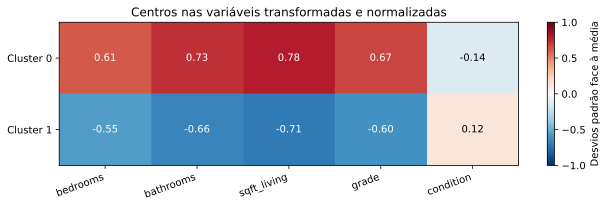

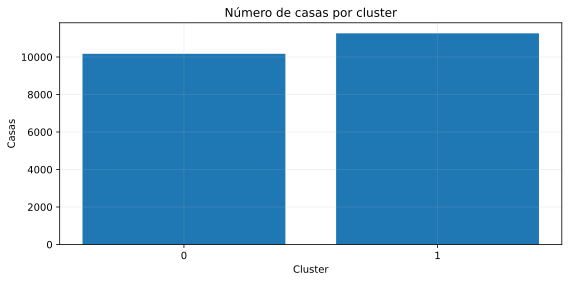

In [7]:
resultado = casas.copy()
resultado["Cluster"] = melhor["grupos"]
# O perfil usa os mesmos valores imputados que entraram no modelo, em unidades originais.
resultado[VARIAVEIS] = valores.to_numpy()
tamanhos = resultado.groupby("Cluster").size().rename("casas")
perfil = resultado.groupby("Cluster")[VARIAVEIS].median()
perfil.insert(0, "casas", tamanhos)
perfil.insert(1, "percentagem", tamanhos / len(resultado) * 100)
perfil["área_mediana_m2"] = perfil["sqft_living"] * 0.09290304
display(perfil.round(2))
print("Dispersão: percentis 25 e 75 em cada grupo")
display(resultado.groupby("Cluster")[VARIAVEIS].quantile([0.25, 0.75]).round(2))

centros_tabela = pd.DataFrame(
    melhor["centros"], columns=VARIAVEIS,
    index=pd.Index(range(K_ESCOLHIDO), name="Cluster")
)
limite = max(1.0, float(np.abs(centros_tabela.to_numpy()).max()))
fig, eixo = plt.subplots(figsize=(9, max(3, K_ESCOLHIDO * 0.55)))
mapa = eixo.imshow(centros_tabela, cmap="RdBu_r", vmin=-limite, vmax=limite, aspect="auto")
eixo.set_xticks(range(len(VARIAVEIS)), VARIAVEIS, rotation=20, ha="right")
eixo.set_yticks(range(K_ESCOLHIDO), [f"Cluster {i}" for i in range(K_ESCOLHIDO)])
eixo.set_title("Centros nas variáveis transformadas e normalizadas")
eixo.grid(False)
for i in range(K_ESCOLHIDO):
    for j in range(len(VARIAVEIS)):
        valor = centros_tabela.iloc[i, j]
        eixo.text(j, i, f"{valor:.2f}", ha="center", va="center",
                  color="white" if abs(valor) > limite * 0.55 else "black")
fig.colorbar(mapa, ax=eixo, label="Desvios padrão face à média")
fig.tight_layout()
plt.show()

fig, eixo = plt.subplots()
eixo.bar(tamanhos.index.astype(str), tamanhos.values)
eixo.set(title="Número de casas por cluster", xlabel="Cluster", ylabel="Casas")
plt.show()


In [8]:
descritores = resultado.assign(
    frente_agua_pct=resultado["waterfront"] * 100,
    renovada_pct=resultado["yr_renovated"].gt(0) * 100,
)
contexto = descritores.groupby("Cluster").agg(
    preço_mediano_USD=("price", "median"),
    preço_p25_USD=("price", lambda s: s.quantile(0.25)),
    preço_p75_USD=("price", lambda s: s.quantile(0.75)),
    ano_construção_mediano=("yr_built", "median"),
    vista_mediana=("view", "median"),
    frente_agua_pct=("frente_agua_pct", "mean"),
    renovada_pct=("renovada_pct", "mean"),
)
display(contexto.round(2))
print("Três códigos postais mais frequentes por cluster; percentagem dentro do cluster")
por_codigo = (
    resultado.groupby(["Cluster", "zipcode"]).size().rename("casas")
    .reset_index()
)
por_codigo["percentagem_no_cluster"] = (
    por_codigo["casas"] / por_codigo["Cluster"].map(tamanhos) * 100
)
display(
    por_codigo.sort_values(["Cluster", "casas", "zipcode"], ascending=[True, False, True])
    .groupby("Cluster", sort=False).head(3).round(2).reset_index(drop=True)
)


,preço_mediano_USD,preço_p25_USD,preço_p75_USD,ano_construção_mediano,vista_mediana,frente_agua_pct,renovada_pct
Cluster,,,,,,,
0,604000.0,438000.0,822500.0,1989.0,0.0,1.16,4.94
1,362950.0,269500.0,477500.0,1960.0,0.0,0.40,3.61


Três códigos postais mais frequentes por cluster; percentagem dentro do cluster


,Cluster,zipcode,casas,percentagem_no_cluster
0,0,98052,398,3.91
1,0,98006,384,3.77
2,0,98038,348,3.42
3,1,98103,452,4.01
4,1,98117,399,3.54
5,1,98115,388,3.44


## 6. Estabilidade perante a inicialização

A estabilidade da solução selecionada é avaliada com as sementes 42, 43 e 44, mantendo dez inicializações por semente. Para cada execução, registam-se a inércia, a dimensão dos grupos e o índice de Rand ajustado (ARI) face à partição da experiência principal.

O ARI mede a concordância entre duas partições, independentemente dos identificadores atribuídos aos clusters. Um valor de 1 corresponde a partições iguais; valores próximos de zero indicam concordância semelhante à esperada ao acaso. A implementação é verificada com exemplos de resultado conhecido.

In [9]:
def rand_ajustado(grupos_a, grupos_b):
    a, b = np.asarray(grupos_a), np.asarray(grupos_b)
    if a.ndim != 1 or b.shape != a.shape or len(a) < 2:
        raise ValueError("São necessários dois vetores alinhados, com pelo menos dois registos.")
    _, a = np.unique(a, return_inverse=True)
    _, b = np.unique(b, return_inverse=True)
    tabela = np.zeros((a.max() + 1, b.max() + 1), dtype=np.int64)
    np.add.at(tabela, (a, b), 1)

    combinacoes = lambda n: n * (n - 1) / 2
    pares = combinacoes(len(a))
    juntos = combinacoes(tabela).sum()
    linhas = combinacoes(tabela.sum(axis=1)).sum()
    colunas = combinacoes(tabela.sum(axis=0)).sum()
    acaso = linhas * colunas / pares
    denominador = (linhas + colunas) / 2 - acaso
    return 1.0 if abs(denominador) < 1e-12 else float((juntos - acaso) / denominador)


assert np.isclose(rand_ajustado([0, 0, 1, 1], [1, 1, 0, 0]), 1.0)
assert np.isclose(rand_ajustado([0, 0, 1, 1], [0, 1, 0, 1]), -0.5)

sensibilidade = []
for semente in [SEMENTE, SEMENTE + 1, SEMENTE + 2]:
    modelo = melhor if semente == SEMENTE else kmeans_raiz(
        X, K_ESCOLHIDO, semente=semente,
        n_init=N_INICIALIZACOES, max_iter=MAX_ITERACOES
    )
    sensibilidade.append({
        "semente": semente,
        "inercia": modelo["inercia"],
        "ARI_face_à_primeira": rand_ajustado(melhor["grupos"], modelo["grupos"]),
        "tamanhos_ordenados": sorted(np.bincount(modelo["grupos"]).tolist()),
    })
display(pd.DataFrame(sensibilidade))

,semente,inercia,ARI_face_à_primeira,tamanhos_ordenados
0,42,68726.145781,1.0,"[10173, 11263]"
1,43,68726.145781,1.0,"[10173, 11263]"
2,44,68726.145781,1.0,"[10173, 11263]"


## 7. Resultados e discussão

A execução apresentada utilizou o CSV original de King County. As **21 613 vendas** correspondem a **21 436 imóveis distintos**. Identificaram-se 176 imóveis com várias vendas: 175 com duas observações e um com três. As cinco características de segmentação mantêm-se constantes entre as vendas destes imóveis. Foi aplicada uma correção de 33 para 3 quartos e não foi necessária a imputação de valores nas variáveis selecionadas.

### Seleção de K

A solução com **K=2** obteve a maior silhouette na amostra de 500 imóveis: **0,3372**, face a 0,2836 para K=3. A inércia diminuiu de 68 726,15 para 56 779,73 entre estas duas configurações, mas a divisão adicional reduziu a silhouette. Selecionou-se, por isso, K=2 para a análise dos perfis.

### Perfis identificados

| Indicador | Cluster 0 | Cluster 1 |
|---|---:|---:|
| Imóveis | 10 173 (47,46%) | 11 263 (52,54%) |
| Quartos — mediana | 4 | 3 |
| Casas de banho — mediana | 2,50 | 1,75 |
| Área habitável — mediana | 240,62 m² | 135,64 m² |
| Qualidade da construção — mediana | 8 | 7 |
| Estado de conservação — mediana | 3 | 3 |
| Ano de construção — mediana | 1989 | 1960 |
| Preço da última venda — mediana | 604 000 USD | 362 950 USD |

O **cluster 0** concentra imóveis de maior dimensão, com mais quartos e casas de banho e qualidade de construção superior. O **cluster 1** apresenta menor área habitável e menor classificação mediana de qualidade. Os dois grupos têm dimensões próximas, representando 47,46% e 52,54% dos imóveis.

O estado de conservação apresenta mediana 3 e intervalo interquartil de 3 a 4 em ambos os clusters. A diferenciação observada está, assim, sobretudo associada à dimensão, ao equipamento e à qualidade de construção. Nos descritores complementares, o cluster 0 apresenta também um ano de construção mediano mais recente e um preço mediano superior.

### Estabilidade e aplicação

As três sementes avaliadas produziram a mesma inércia e **ARI=1** face à partição principal, evidenciando estabilidade perante as inicializações testadas.

A segmentação obtida fornece um critério inicial de organização da oferta em dois perfis físicos. A comparação de imóveis dentro de cada perfil pode ser complementada por localização e preço, de acordo com o contexto de utilização.

## 8. Limitações e trabalho futuro

A interpretação dos resultados considera as seguintes limitações:

- **Âmbito dos dados.** A amostra contém imóveis vendidos em 2014–2015. A extrapolação para outros períodos ou para a totalidade do parque habitacional exige dados adicionais.
- **Qualidade dos registos.** A correção de 33 para 3 quartos constitui uma hipótese de tratamento. Os zeros em quartos e casas de banho podem refletir informação por registar; o efeito destas decisões na segmentação permanece por avaliar.
- **Representação dos imóveis.** A seleção das variáveis privilegia os perfis físicos. Qualidade e estado são tratados como escalas numéricas, assumindo intervalos iguais entre níveis. A correlação entre área, quartos e casas de banho pode reforçar o peso da dimensão na segmentação.
- **Seleção e estabilidade do modelo.** A pesquisa de K está limitada ao intervalo de 2 a 8 e a silhouette é aproximada numa única amostra. A avaliação de estabilidade abrange a inicialização, mantendo os dados e a preparação fixos.
- **Interpretação económica.** Os preços são descritores históricos dos grupos. A análise não estima desvios face ao valor esperado nem mede o efeito da segmentação em resultados comerciais.

O desenvolvimento da análise pode incluir outras amostras para a silhouette, avaliação da sensibilidade ao tratamento de registos atípicos e comparação de diferentes conjuntos de variáveis. A inclusão de localização, terreno ou idade do imóvel permitiria explorar segmentações orientadas para objetivos complementares.